<a href="https://colab.research.google.com/github/22040223-max/Machine-Deep-Learning/blob/main/Unidad%204/ProyectoU4_Segmentacion_Estudiantes_Redes_Sociales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Instituto Tecnológico de Durango
## Tecnológico Nacional de México

### Machine Learning y Deep Learning

Unidad 4

Proyecto: **Segmentación de Estudiantes en Redes Sociales con K-Means**

Facilitador: *Dr. José Gabriel Rodríguez Rivas*

Integrantes del equipo:

- Fernández Varela Alan Eduardo
- Salazar Rueda Diego Tristán
- Zapata López Víctor Hugo

## Segmentación de Estudiantes en Redes Sociales

**Objetivo:**

- Agrupar a los estudiantes según los intereses que muestran en su perfil de red social usando K-Means (clustering no supervisado).
- Usar PCA para reducir la dimensionalidad, ver qué variables pesan más en cada componente y poder graficar los grupos.
- Interpretar cada clúster para saber qué tipo de estudiante representa.

## Cargar librerías y dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

estudiantes = pd.read_csv("Students Social Network Profile.csv")
estudiantes.head()

,gradyear,gender,age,NumberOffriends,basketball,football,soccer,softball,volleyball,swimming,...,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs
0,2007,NaN,NaN,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2007,F,17.41,49,0,0,1,0,0,1,...,0,0,0,0,0,0,0,0,1,0
2,2007,F,17.511,41,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,1,1
3,2006,F,NaN,36,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2008,F,16.657,1,0,0,0,0,0,1,...,0,0,0,3,0,0,0,0,0,0


## Exploración del dataset

In [ ]:
print("Filas y columnas:", estudiantes.shape)
estudiantes.info()

Filas y columnas: (15000, 40)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 40 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   gradyear         15000 non-null  int64 
 1   gender           13663 non-null  object
 2   age              12504 non-null  object
 3   NumberOffriends  15000 non-null  int64 
 4   basketball       15000 non-null  int64 
 5   football         15000 non-null  int64 
 6   soccer           15000 non-null  int64 
 7   softball         15000 non-null  int64 
 8   volleyball       15000 non-null  int64 
 9   swimming         15000 non-null  int64 
 10  cheerleading     15000 non-null  int64 
 11  baseball         15000 non-null  int64 
 12  tennis           15000 non-null  int64 
 13  sports           15000 non-null  int64 
 14  cute             15000 non-null  int64 
 15  sex              15000 non-null  int64 
 16  sexy             15000 non-null  int64 
 17  h

In [ ]:
estudiantes.describe().T

,count,mean,std,min,25%,50%,75%,max
gradyear,15000.0,2007.496933,1.116516,2006.0,2006.0,2008.0,2008.0,2009.0
NumberOffriends,15000.0,29.834533,35.386649,0.0,3.0,20.0,44.0,605.0
basketball,15000.0,0.267000,0.788851,0.0,0.0,0.0,0.0,22.0
football,15000.0,0.255467,0.702260,0.0,0.0,0.0,0.0,9.0
soccer,15000.0,0.222000,0.920420,0.0,0.0,0.0,0.0,22.0
softball,15000.0,0.159667,0.737344,0.0,0.0,0.0,0.0,17.0
volleyball,15000.0,0.142933,0.638747,0.0,0.0,0.0,0.0,14.0
swimming,15000.0,0.135000,0.548691,0.0,0.0,0.0,0.0,31.0
cheerleading,15000.0,0.105133,0.502491,0.0,0.0,0.0,0.0,8.0
baseball,15000.0,0.104133,0.519205,0.0,0.0,0.0,0.0,14.0


In [ ]:
print("Valores nulos por columna:")
print(estudiantes.isnull().sum()[estudiantes.isnull().sum() > 0])

print("\nDistribución por género:")
print(estudiantes["gender"].value_counts(dropna=False))

Valores nulos por columna:
gender    1337
age       2496
dtype: int64

Distribución por género:
gender
F      11057
M       2606
NaN     1337
Name: count, dtype: int64


**Lo que observamos:**

- El dataset tiene 15,000 estudiantes y 40 columnas.
- Las primeras 4 columnas son datos generales del estudiante (año de graduación, género, edad y número de amigos).
- Las otras 36 columnas son palabras, y el valor es cuántas veces aparece esa palabra en el perfil del estudiante.
- Solo `gender` (1,337) y `age` (2,496) tienen valores nulos. Además `age` viene como texto y trae algunos valores mal capturados (por ejemplo "16. Jun"), por eso no la usamos en el clustering.
- La mayoría de las palabras tienen promedio menor a 1 y mediana 0, o sea que la mayoría de los estudiantes casi no las menciona, pero hay algunos con valores muy altos (por ejemplo `blonde` llega a 327 y `sex` a 114).
- Hay muchas más mujeres (11,057) que hombres (2,606).

## Descripción de las variables

| Variable | Tipo | Descripción |
|---|---|---|
| gradyear | numérica (int) | Año de graduación del estudiante (2006 a 2009). |
| gender | categórica | Género del estudiante (F = mujer, M = hombre). |
| age | texto | Edad del estudiante. Tiene nulos y valores mal capturados. |
| NumberOffriends | numérica (int) | Número de amigos que tiene en la red social. |
| basketball, football, soccer, softball, volleyball, swimming, cheerleading, baseball, tennis, sports | numérica (int) | Veces que menciona palabras de **deportes**. |
| cute, sex, sexy, hot, kissed | numérica (int) | Veces que menciona palabras de **relaciones / atracción**. |
| dance, band, marching, music, rock | numérica (int) | Veces que menciona palabras de **música y baile**. |
| god, church, jesus, bible | numérica (int) | Veces que menciona palabras de **religión**. |
| hair, dress, blonde, mall, shopping, clothes, hollister, abercrombie | numérica (int) | Veces que menciona palabras de **moda y compras**. |
| die, death, drunk, drugs | numérica (int) | Veces que menciona palabras de **conductas de riesgo**. |

Para el clustering usamos las 36 variables de palabras, porque son las que describen los intereses del estudiante. `gender` y `NumberOffriends` las dejamos solo para describir los grupos al final.

## Selección de variables relevantes

In [ ]:
features = list(estudiantes.columns[4:])
print("Número de variables:", len(features))

X = estudiantes[features]
X.head()

Número de variables: 36


,basketball,football,soccer,softball,volleyball,swimming,cheerleading,baseball,tennis,sports,...,blonde,mall,shopping,clothes,hollister,abercrombie,die,death,drunk,drugs
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,1,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
2,0,0,0,0,0,0,0,1,0,0,...,0,1,0,0,0,0,0,0,1,1
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,1,0,0,3,0,...,0,0,0,3,0,0,0,0,0,0


## Escalamiento de las variables

Se aplica StandardScaler para que todas las palabras queden en la misma escala y que las que tienen valores muy grandes no dominen al algoritmo.

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## Análisis de Componentes Principales (PCA)

Primero calculamos el PCA con todos los componentes para ver cuánta varianza explica cada uno.

In [ ]:
pca_full = PCA()
pca_full.fit(X_scaled)

print("Varianza por componente:", pca_full.explained_variance_ratio_.round(4))
print("\nVarianza acumulada:", pca_full.explained_variance_ratio_.cumsum().round(4))

Varianza por componente: [0.093  0.0499 0.0458 0.0426 0.0405 0.0346 0.031  0.0306 0.0291 0.029
 0.0283 0.0272 0.0271 0.0267 0.0267 0.0261 0.0253 0.025  0.0246 0.0242
 0.0238 0.0229 0.0228 0.0226 0.0221 0.0218 0.0213 0.0206 0.0203 0.0195
 0.0186 0.0179 0.0159 0.0156 0.0147 0.0126]

Varianza acumulada: [0.093  0.1428 0.1886 0.2312 0.2717 0.3062 0.3372 0.3678 0.3969 0.4259
 0.4542 0.4814 0.5084 0.5352 0.5618 0.5879 0.6132 0.6383 0.6629 0.6871
 0.7108 0.7338 0.7566 0.7791 0.8012 0.823  0.8443 0.8649 0.8852 0.9047
 0.9233 0.9412 0.9571 0.9728 0.9874 1.    ]


### Scree Plot (Gráfica de Codo del PCA)

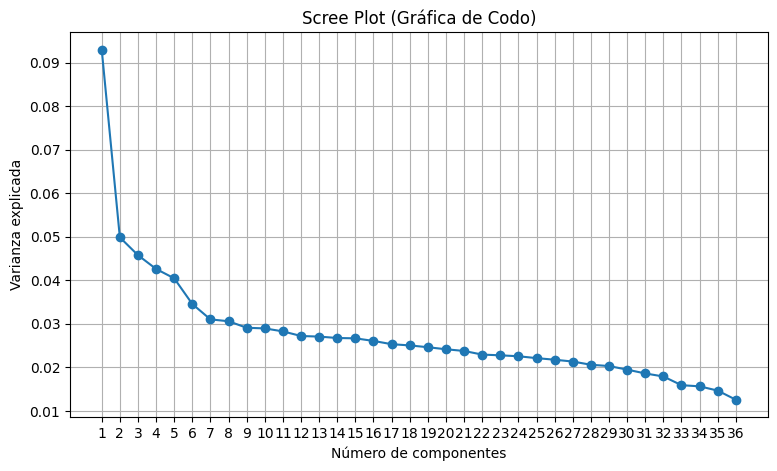

In [ ]:
plt.figure(figsize=(9,5))
plt.plot(
    range(1, len(pca_full.explained_variance_ratio_) + 1),
    pca_full.explained_variance_ratio_,
    marker="o"
)
plt.xticks(range(1, len(pca_full.explained_variance_ratio_) + 1))
plt.xlabel("Número de componentes")
plt.ylabel("Varianza explicada")
plt.title("Scree Plot (Gráfica de Codo)")
plt.grid(True)
plt.show()

**Interpretación**

- PC1 explica aproximadamente el 9.3% de la varianza y PC2 el 5%. Entre los dos solo juntan el 14.3%.
- El codo se ve en el componente 2, después la curva baja muy despacio (cada componente aporta entre 4% y 1%).
- Con 4 componentes se llega al 23% y para pasar del 70% se necesitan como 21 componentes.
- Esto quiere decir que las palabras están poco correlacionadas entre sí, cada una aporta información diferente, y por eso el PCA no puede resumir el dataset en pocos componentes.
- Por lo anterior, el K-Means lo entrenamos con las 36 variables escaladas y el PCA lo usamos para interpretar y para graficar (PC1 vs PC2 y PC3 vs PC4).

### Coeficientes de las variables

In [ ]:
pca = PCA(n_components=4)
X_pca = pca.fit_transform(X_scaled)

componentes = pd.DataFrame(
    pca.components_,
    columns=X.columns,
    index=[f"PC{i+1}" for i in range(pca.n_components_)]
)
print("Contribución de variables a cada componente:")
componentes.T.round(2)

Contribución de variables a cada componente:


,PC1,PC2,PC3,PC4
basketball,0.14,-0.05,-0.14,0.24
football,0.14,-0.05,-0.10,0.26
soccer,0.07,-0.03,-0.08,0.13
softball,0.07,-0.03,-0.11,0.17
volleyball,0.07,-0.06,-0.16,0.15
swimming,0.09,-0.03,-0.08,0.07
cheerleading,0.09,-0.06,-0.14,0.05
baseball,0.08,-0.02,-0.08,0.21
tennis,0.05,0.00,-0.00,0.11
sports,0.17,-0.06,-0.04,0.20


**Interpretación de los componentes**

**PC1:** todas las variables tienen coeficiente positivo, y las más altas son `hair` (0.36), `kissed` (0.28), `music` (0.25), `clothes` (0.25), `sex`, `rock` y `drugs` (0.22). Representa qué tan activo es el estudiante en su perfil (los que escriben mucho de todo contra los que casi no escriben).

**PC2:** dominan `jesus` (0.54), `god` (0.52), `bible` (0.49) y `church` (0.22). Es claramente el componente de **religión**.

**PC3:** positivos `band` (0.38) y `marching` (0.35), negativos `hollister` (-0.32), `abercrombie` (-0.29) y `shopping` (-0.26). Separa a los de **banda de música** de los de **moda y compras**.

**PC4:** positivos `marching` (0.45), `band` (0.44) y los deportes (`football` 0.26, `basketball` 0.24), negativos `die`, `drunk`, `drugs` y `sex` (alrededor de -0.20). Separa **actividades escolares** (banda y deportes) de las **conductas de riesgo**.

### Gráfica Biplot (PC1 vs PC2)

Los puntos son los estudiantes y las flechas son las variables originales. Se limitaron los ejes porque hay algunos estudiantes con valores muy extremos que aplastan la gráfica.

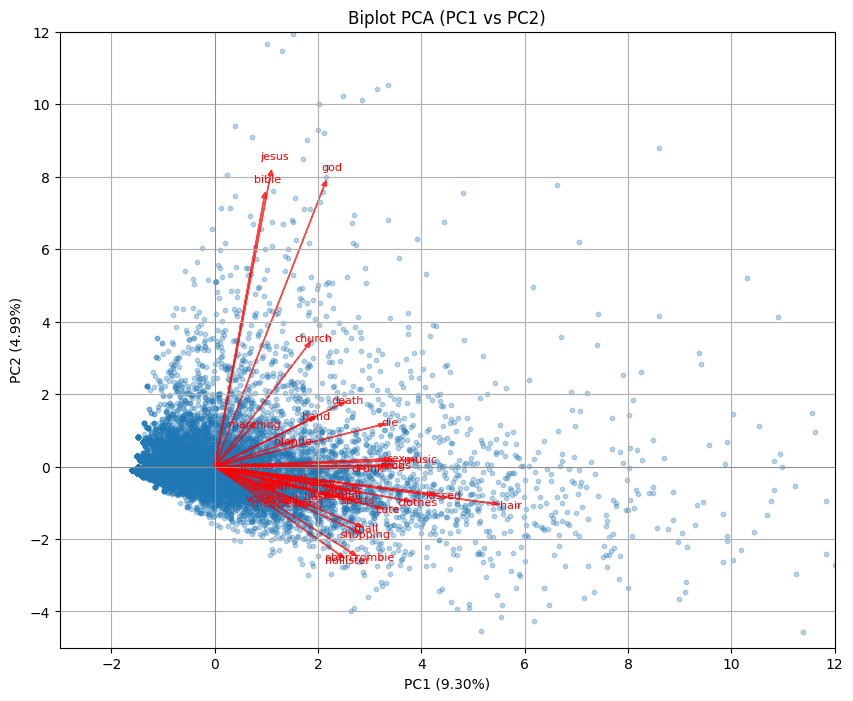

In [ ]:
loadings = pca.components_.T
variables = X.columns

plt.figure(figsize=(10,8))
plt.scatter(X_pca[:,0], X_pca[:,1], alpha=0.3, s=10)

plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}%)")
plt.xlim(-3, 12)
plt.ylim(-5, 12)

for i, var in enumerate(variables):
    plt.arrow(0, 0,
              loadings[i,0]*15,
              loadings[i,1]*15,
              color="red",
              alpha=0.7,
              head_width=0.1)
    plt.text(loadings[i,0]*16,
             loadings[i,1]*16,
             var, color="red", ha="center", va="center", fontsize=8)

plt.title("Biplot PCA (PC1 vs PC2)")
plt.grid(True)
plt.axhline(0, color="gray", lw=0.5)
plt.axvline(0, color="gray", lw=0.5)
plt.show()

**Interpretación**

- Las flechas de `god`, `jesus` y `bible` apuntan hacia arriba y están casi juntas, o sea que están correlacionadas entre sí y son las que forman PC2.
- Casi todas las demás flechas apuntan hacia la derecha (PC1), con `hair`, `kissed`, `music` y `clothes` como las más largas.
- La mayoría de los puntos está amontonada cerca del origen, que son los estudiantes que casi no mencionan ninguna palabra.

### Biplot de componentes PC3 y PC4

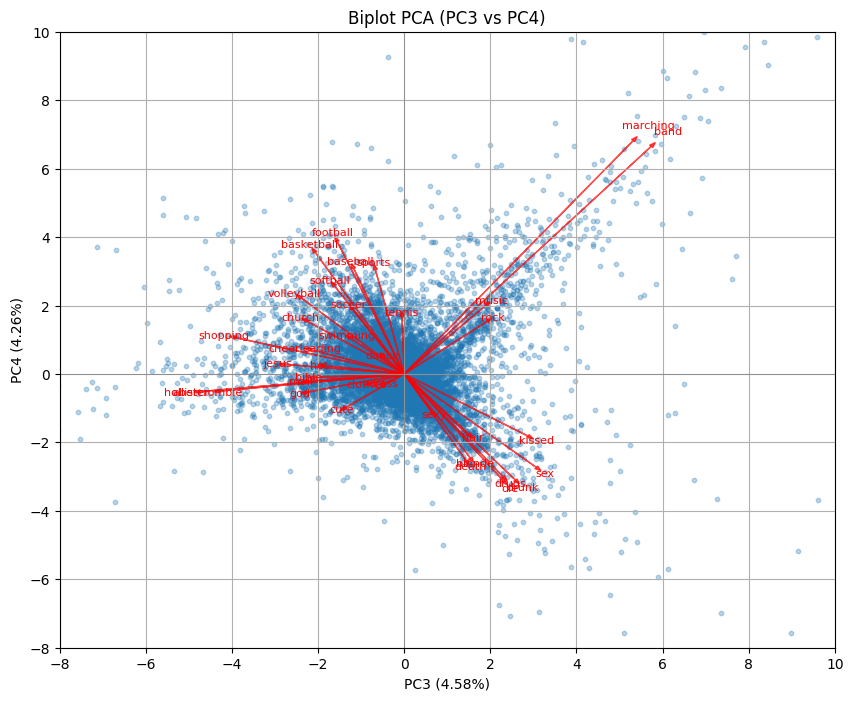

In [ ]:
plt.figure(figsize=(10,8))
plt.scatter(X_pca[:,2], X_pca[:,3], alpha=0.3, s=10)

plt.xlabel(f"PC3 ({pca.explained_variance_ratio_[2]*100:.2f}%)")
plt.ylabel(f"PC4 ({pca.explained_variance_ratio_[3]*100:.2f}%)")
plt.xlim(-8, 10)
plt.ylim(-8, 10)

for i, var in enumerate(variables):
    plt.arrow(0, 0,
              loadings[i,2]*15,
              loadings[i,3]*15,
              color="red",
              alpha=0.7,
              head_width=0.1)
    plt.text(loadings[i,2]*16,
             loadings[i,3]*16,
             var, color="red", ha="center", va="center", fontsize=8)

plt.title("Biplot PCA (PC3 vs PC4)")
plt.grid(True)
plt.axhline(0, color="gray", lw=0.5)
plt.axvline(0, color="gray", lw=0.5)
plt.show()

**Interpretación**

- `band` y `marching` apuntan juntas hacia arriba a la derecha, son las variables que más se distinguen en estos dos componentes.
- Los deportes apuntan hacia arriba a la izquierda, junto con `shopping`, `hollister` y `abercrombie` que se van más a la izquierda.
- `sex`, `drunk`, `drugs`, `die` y `kissed` apuntan hacia abajo a la derecha, del lado contrario a los deportes.
- Aquí ya se alcanzan a ver grupos de intereses diferentes: banda, deportes, moda y conductas de riesgo.

## Determinamos el número óptimo de clústeres (método del codo)

Se entrena K-Means con varios valores de k y se grafica la inercia de cada uno.

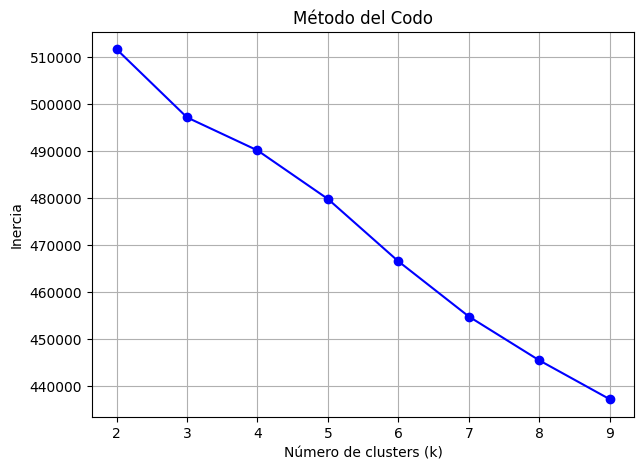

In [ ]:
inertias = []
K = range(2, 10)

for k in K:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(7,5))
plt.plot(K, inertias, "bo-")
plt.title("Método del Codo")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.grid(True)
plt.show()

**Interpretación**

La inercia va bajando casi en línea recta, no se ve un codo bien marcado. Esto pasa porque las variables están poco correlacionadas y los grupos no están muy separados. Por eso también revisamos el silhouette score antes de elegir k.

## Tabla comparativa de inercia y silhouette

In [ ]:
resultados = []

for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=42)
    etiquetas = km.fit_predict(X_scaled)
    resultados.append([k, km.inertia_, silhouette_score(X_scaled, etiquetas)])

tabla = pd.DataFrame(resultados, columns=["k", "Inercia", "Silhouette"])
tabla.round(4)

,k,Inercia,Silhouette
0,2,511565.4676,0.4206
1,3,497075.1280,0.3175
2,4,490067.4105,0.3145
3,5,479740.8241,0.2876
4,6,466492.9397,0.2868
5,7,454769.4505,0.2678


**Interpretación**

- La inercia siempre baja cuando aumenta k, entonces sola no sirve para decidir.
- El silhouette más alto es con k = 2 (0.42), pero al revisarlo solo separa a los estudiantes que escriben poco (12,825) de los que escriben mucho (2,175), y eso no dice nada de sus intereses.
- Con k = 3 y k = 4 el silhouette baja a 0.31 y con k = 5 queda en 0.29, que es una estructura débil pero existente.
- Elegimos **k = 5** porque el silhouette es casi igual al de k = 3 y k = 4, pero los grupos que salen sí se pueden interpretar por tipo de interés.

## K-Means con 5 Clusters

In [ ]:
k = 5
kmeans = KMeans(n_clusters=k, random_state=42)
clusters = kmeans.fit_predict(X_scaled)

estudiantes["cluster"] = clusters

print("Distribución de estudiantes por cluster:")
print(estudiantes.groupby("cluster").size())

print("\nSilhouette score con k = 5:", silhouette_score(X_scaled, clusters))
print("Inercia con k = 5:", kmeans.inertia_)

Distribución de estudiantes por cluster:
cluster
0      492
1      196
2    10581
3     2397
4     1334
dtype: int64

Silhouette score con k = 5: 0.2875668912515465
Inercia con k = 5: 479740.8241431915


## Visualización de los clusters (PC1 vs PC2)

Se agregan los componentes al dataset y se grafican los estudiantes coloreados por cluster, junto con los centroides.

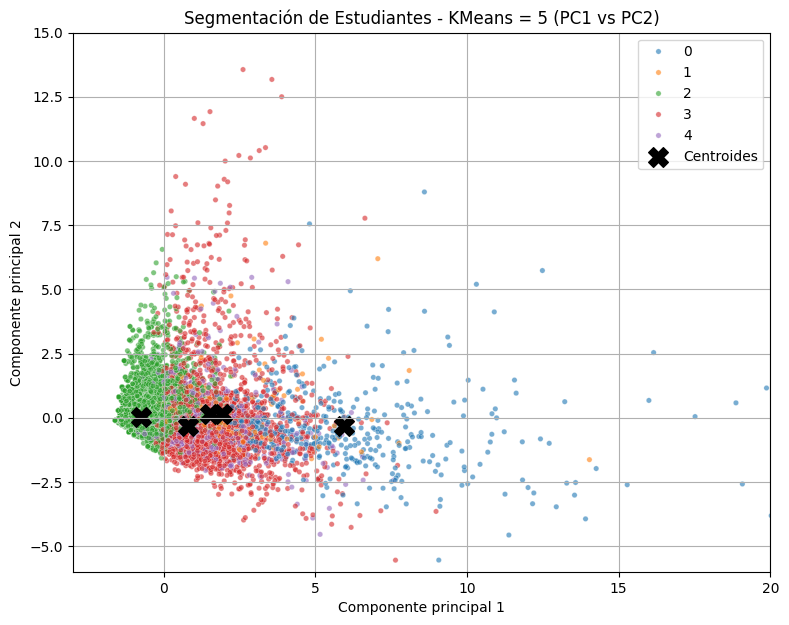

In [ ]:
estudiantes["pca1"] = X_pca[:, 0]
estudiantes["pca2"] = X_pca[:, 1]
estudiantes["pca3"] = X_pca[:, 2]
estudiantes["pca4"] = X_pca[:, 3]

centroids_pca = pca.transform(kmeans.cluster_centers_)

plt.figure(figsize=(9,7))
sns.scatterplot(data=estudiantes, x="pca1", y="pca2", hue="cluster", palette="tab10", s=15, alpha=0.6)
plt.scatter(centroids_pca[:,0], centroids_pca[:,1], s=200, c="black", marker="X", label="Centroides")
plt.title("Segmentación de Estudiantes - KMeans = 5 (PC1 vs PC2)")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.xlim(-3, 20)
plt.ylim(-6, 15)
plt.grid(True)
plt.legend()
plt.show()

**Interpretación**

- El cluster 2 está pegado al origen, son los estudiantes con poca actividad.
- Los clusters 3 y 4 quedan un poco más a la derecha y encimados entre ellos, porque en PC1 y PC2 no se distingue la moda de los deportes.
- El cluster 0 es el que más se va a la derecha (PC1 alto), son los que más palabras mencionan.
- Los grupos se enciman bastante, lo cual es normal porque PC1 y PC2 solo explican el 14.3% de la varianza.

## Visualización de los clusters (PC3 vs PC4)

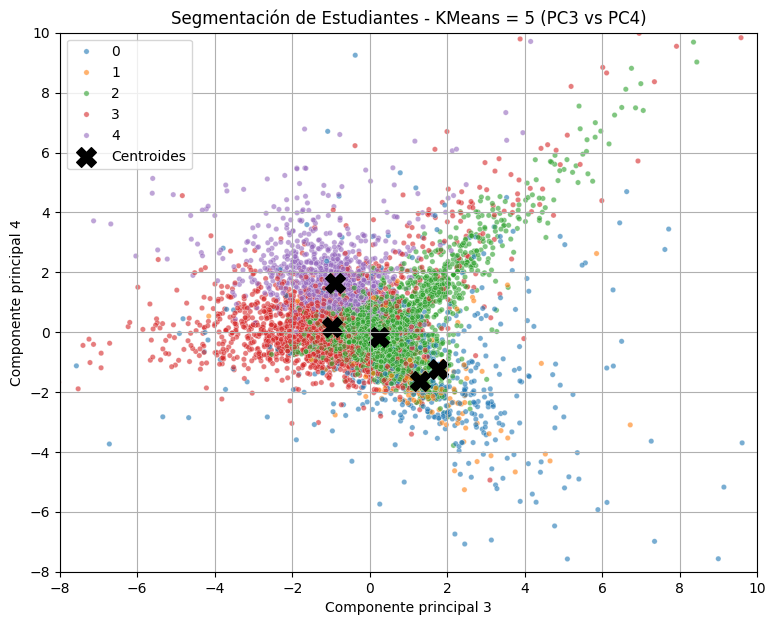

In [ ]:
plt.figure(figsize=(9,7))
sns.scatterplot(data=estudiantes, x="pca3", y="pca4", hue="cluster", palette="tab10", s=15, alpha=0.6)
plt.scatter(centroids_pca[:,2], centroids_pca[:,3], s=200, c="black", marker="X", label="Centroides")
plt.title("Segmentación de Estudiantes - KMeans = 5 (PC3 vs PC4)")
plt.xlabel("Componente principal 3")
plt.ylabel("Componente principal 4")
plt.xlim(-8, 10)
plt.ylim(-8, 10)
plt.grid(True)
plt.legend()
plt.show()

**Interpretación**

En PC3 y PC4 los grupos se separan mejor que en la gráfica anterior: los clusters 3 y 4 (moda y deportes) se van hacia la izquierda y hacia arriba, y los clusters 0 y 1 (conductas de riesgo) se van hacia abajo a la derecha, igual que las flechas que vimos en el biplot.

## Análisis descriptivo de cada clúster

In [ ]:
resumen = estudiantes.groupby("cluster")[features].mean().round(2)
print("Promedios por clúster:")
resumen.T

Promedios por clúster:


cluster,0,1,2,3,4
basketball,0.66,0.24,0.12,0.26,1.32
football,0.54,0.40,0.12,0.31,1.13
soccer,0.40,0.24,0.13,0.23,0.86
softball,0.24,0.15,0.06,0.13,1.00
volleyball,0.21,0.18,0.06,0.12,0.83
swimming,0.28,0.19,0.09,0.27,0.20
cheerleading,0.26,0.10,0.05,0.31,0.14
baseball,0.26,0.06,0.03,0.08,0.65
tennis,0.15,0.08,0.06,0.17,0.15
sports,0.54,0.20,0.07,0.12,0.66


In [ ]:
print("Promedio de amigos por clúster:")
print(estudiantes.groupby("cluster")["NumberOffriends"].mean().round(1))

print("\nProporción de género por clúster:")
print(pd.crosstab(estudiantes["cluster"], estudiantes["gender"], normalize="index").round(2))

Promedio de amigos por clúster:
cluster
0    28.9
1    36.0
2    27.3
3    37.3
4    36.3
Name: NumberOffriends, dtype: float64

Proporción de género por clúster:
gender      F     M
cluster            
0        0.87  0.13
1        0.81  0.19
2        0.78  0.22
3        0.95  0.05
4        0.73  0.27


## Interpretación de los clústeres

| Cluster | Estudiantes | Palabras con promedio más alto | Perfil |
|---|---|---|---|
| 0 | 492 (3.3%) | hair 3.50, sex 2.54, music 2.26, kissed 1.70, die 1.30, rock 1.28, drugs 1.04 | Muy activos / conductas de riesgo |
| 1 | 196 (1.3%) | drunk 2.67, blonde 1.77 | Alcohol / fiesta |
| 2 | 10,581 (70.5%) | Todas bajas (music 0.56, god 0.31) | Poca actividad |
| 3 | 2,397 (16.0%) | dance 1.19, shopping 1.04, cute 0.90, mall 0.72, church 0.69 | Moda, compras y vida social |
| 4 | 1,334 (8.9%) | basketball 1.32, football 1.13, softball 1.00, soccer 0.86, volleyball 0.83 | Deportistas |

**Cluster 0 - Muy activos con conductas de riesgo**

- Es un grupo chico pero es el que más escribe en su perfil.
- Tiene los promedios más altos en `sex`, `kissed`, `drugs`, `die` y también en `music`, `rock` y `hair`.
- Son estudiantes que hablan de relaciones, drogas y música. Sería el grupo al que más atención habría que ponerle.

**Cluster 1 - Alcohol**

- Es el grupo más pequeño (196 estudiantes).
- Lo que lo distingue es `drunk` (2.67, cuando en los demás grupos es menor a 0.6) y `blonde`.
- En lo demás se parecen al promedio, o sea que el algoritmo los separó casi solo por mencionar mucho la palabra drunk.

**Cluster 2 - Poca actividad**

- Es el más grande, con el 70% de los estudiantes.
- Tiene los promedios más bajos en todas las palabras y también el menor número de amigos (27.3).
- Son estudiantes que casi no escriben en su perfil, entonces no se les puede asignar un interés en particular.

**Cluster 3 - Moda, compras y vida social**

- Promedios altos en `shopping`, `mall`, `dance`, `cute`, `dress`, `hollister` y `abercrombie`. También son los que más mencionan `church` y `god`.
- El 95% son mujeres y es el grupo con más amigos (37.3).
- Son estudiantes sociables, interesadas en la ropa, salir de compras y el baile.

**Cluster 4 - Deportistas**

- Tiene los promedios más altos en casi todos los deportes (`basketball`, `football`, `softball`, `soccer`, `volleyball`, `baseball`).
- Es el grupo con más proporción de hombres (27%) y también tiene muchos amigos (36.3).
- Son estudiantes que participan en equipos deportivos de la escuela.

## Conclusiones

- Con K-Means se pudieron identificar 5 grupos de estudiantes según sus intereses: muy activos con conductas de riesgo, alcohol, poca actividad, moda y vida social, y deportistas.
- El método del codo no mostró un codo claro, por eso la decisión de k se apoyó en la tabla de inercia y silhouette y en que los grupos se pudieran interpretar. El k = 2 tenía mejor silhouette (0.42) pero solo separaba por cantidad de actividad, y con k = 5 (0.29) los grupos sí tienen sentido.
- El silhouette de 0.29 indica que los clusters no están muy separados. Esto se debe a que el 70% de los estudiantes casi no menciona ninguna palabra y quedan todos en un mismo grupo grande.
- El PCA no logró reducir mucho la dimensionalidad (PC1 y PC2 solo explican el 14.3%), porque las 36 palabras están poco correlacionadas. Aun así sirvió para interpretar: PC1 mide la actividad general, PC2 la religión, PC3 banda contra moda y PC4 actividades escolares contra conductas de riesgo.
- En la gráfica de PC3 vs PC4 los grupos se distinguen mejor que en PC1 vs PC2, por eso fue necesario revisar más de dos componentes.
- Los clusters 3 y 4 son los que tienen más amigos, lo que indica que los estudiantes que participan en deportes o actividades sociales tienen más contactos en la red.
- Este tipo de segmentación le puede servir a una escuela o a una empresa para dirigir campañas o programas a cada tipo de estudiante, por ejemplo programas de prevención para los clusters 0 y 1.